In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
import pickle
import os
import streamlit as st

In [3]:
df = pd.read_csv('modified_data.csv')

In [4]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.00,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.00,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.00,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.00,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.00,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09,308166.67,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,204.08
4596,2014-07-09,534333.33,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,365.98
4597,2014-07-09,416904.17,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,138.51
4598,2014-07-10,203400.00,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,97.32


In [5]:
#See the rows and columns
df.shape

(4600, 18)

In [6]:
#first five rows
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51


In [7]:
print(df.dtypes)

date               object
price             float64
bedrooms          float64
bathrooms         float64
sqft_living         int64
sqft_lot            int64
floors            float64
waterfront          int64
view                int64
condition           int64
sqft_above          int64
sqft_basement       int64
yr_built            int64
yr_renovated        int64
street             object
city               object
statezip           object
price_per_sqft    float64
dtype: object


In [8]:
#check missing values 
df.isnull().sum()

date              0
price             0
bedrooms          0
bathrooms         0
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
street            0
city              0
statezip          0
price_per_sqft    0
dtype: int64

In [9]:
#check duplicate rows
df.duplicated().sum()

0

In [10]:
#find a numerical columns
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261,265.876209
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536,357.503362
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000,180.817500
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000,243.855000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000,314.840000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000,22533.900000


In [11]:
#it shows all different city names
df['city'].unique()

array(['Shoreline', 'Seattle', 'Kent', 'Bellevue', 'Redmond',
       'Maple Valley', 'North Bend', 'Lake Forest Park', 'Sammamish',
       'Auburn', 'Des Moines', 'Bothell', 'Federal Way', 'Kirkland',
       'Issaquah', 'Woodinville', 'Normandy Park', 'Fall City', 'Renton',
       'Carnation', 'Snoqualmie', 'Duvall', 'Burien', 'Covington',
       'Inglewood-Finn Hill', 'Kenmore', 'Newcastle', 'Mercer Island',
       'Black Diamond', 'Ravensdale', 'Clyde Hill', 'Algona', 'Skykomish',
       'Tukwila', 'Vashon', 'Yarrow Point', 'SeaTac', 'Medina',
       'Enumclaw', 'Snoqualmie Pass', 'Pacific', 'Beaux Arts Village',
       'Preston', 'Milton'], dtype=object)

In [12]:
#find how may houses are listed in each city
df['city'].value_counts()

city
Seattle                1573
Renton                  293
Bellevue                286
Redmond                 235
Issaquah                187
Kirkland                187
Kent                    185
Auburn                  176
Sammamish               175
Federal Way             148
Shoreline               123
Woodinville             115
Maple Valley             96
Mercer Island            86
Burien                   74
Snoqualmie               71
Kenmore                  66
Des Moines               58
North Bend               50
Covington                43
Duvall                   42
Lake Forest Park         36
Bothell                  33
Newcastle                33
SeaTac                   29
Tukwila                  29
Vashon                   29
Enumclaw                 28
Carnation                22
Normandy Park            18
Clyde Hill               11
Medina                   11
Fall City                11
Black Diamond             9
Ravensdale                7
Pacific        

In [13]:
#check the target variable
df['price'].describe()

count    4.600000e+03
mean     5.519630e+05
std      5.638347e+05
min      0.000000e+00
25%      3.228750e+05
50%      4.609435e+05
75%      6.549625e+05
max      2.659000e+07
Name: price, dtype: float64

In [14]:
#how many houses have price=0
(df['price']==0).sum()

49

In [15]:
df[df['price']==0]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
4354,2014-05-05,0.0,3.0,1.75,1490,10125,1.0,0,0,4,1490,0,1962,0,3911 S 328th St,Federal Way,WA 98001,0.0
4356,2014-05-05,0.0,4.0,2.75,2600,5390,1.0,0,0,4,1300,1300,1960,2001,2120 31st Ave W,Seattle,WA 98199,0.0
4357,2014-05-05,0.0,6.0,2.75,3200,9200,1.0,0,2,4,1600,1600,1953,1983,12271 Marine View Dr SW,Burien,WA 98146,0.0
4358,2014-05-06,0.0,5.0,3.50,3480,36615,2.0,0,0,4,2490,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,0.0
4361,2014-05-07,0.0,5.0,1.50,1500,7112,1.0,0,0,5,760,740,1920,0,14901-14999 12th Ave SW,Burien,WA 98166,0.0
4362,2014-05-07,0.0,4.0,4.00,3680,18804,2.0,0,0,3,3680,0,1990,2009,1223-1237 244th Ave NE,Sammamish,WA 98074,0.0
4374,2014-05-09,0.0,2.0,2.50,2200,188200,1.0,0,3,3,2200,0,2007,0,39612 254th Ave SE,Enumclaw,WA 98022,0.0
4376,2014-05-09,0.0,4.0,2.25,2170,10500,1.0,0,2,4,1270,900,1960,2001,216 SW 183rd St,Normandy Park,WA 98166,0.0
4382,2014-05-12,0.0,5.0,4.50,4630,6324,2.0,0,0,3,3210,1420,2006,0,6925 Oakmont Ave SE,Snoqualmie,WA 98065,0.0
4383,2014-05-13,0.0,5.0,4.00,4430,9000,2.0,0,0,3,4430,0,2013,1923,9235 NE 5th St,Bellevue,WA 98004,0.0


In [16]:
df.loc[df['price']==0,['price','bedrooms','sqft_living']]

,price,bedrooms,sqft_living
4354,0.0,3.0,1490
4356,0.0,4.0,2600
4357,0.0,6.0,3200
4358,0.0,5.0,3480
4361,0.0,5.0,1500
4362,0.0,4.0,3680
4374,0.0,2.0,2200
4376,0.0,4.0,2170
4382,0.0,5.0,4630
4383,0.0,5.0,4430


In [17]:
#Check whether price_per_sqft is also 0 for these houses
df.loc[df['price']==0,['price','bedrooms','sqft_living']].head()

,price,bedrooms,sqft_living
4354,0.0,3.0,1490
4356,0.0,4.0,2600
4357,0.0,6.0,3200
4358,0.0,5.0,3480
4361,0.0,5.0,1500


In [18]:
#check all 49 zeros price rows
df[df['price']==0].describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft
count,49.0,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.000000,49.0
mean,0.0,3.979592,2.698980,2787.142857,16453.306122,1.500000,0.061224,0.795918,3.673469,2295.714286,491.428571,1969.918367,812.714286,0.0
std,0.0,1.108486,1.194584,1354.375625,27739.227932,0.520416,0.242226,1.485760,0.826331,1337.148708,612.726149,27.247964,988.903054,0.0
min,0.0,1.000000,1.000000,720.000000,3500.000000,1.000000,0.000000,0.000000,2.000000,720.000000,0.000000,1920.000000,0.000000,0.0
25%,0.0,3.000000,2.000000,1910.000000,6863.000000,1.000000,0.000000,0.000000,3.000000,1310.000000,0.000000,1952.000000,0.000000,0.0
50%,0.0,4.000000,2.500000,2600.000000,9000.000000,1.500000,0.000000,0.000000,3.000000,1990.000000,0.000000,1962.000000,0.000000,0.0
75%,0.0,5.000000,3.500000,3500.000000,13783.000000,2.000000,0.000000,0.000000,4.000000,3020.000000,900.000000,1998.000000,1999.000000,0.0
max,0.0,6.000000,6.250000,8020.000000,188200.000000,3.000000,1.000000,4.000000,5.000000,8020.000000,1950.000000,2013.000000,2009.000000,0.0


In [19]:
#it is tells us the percentage of rows with invalid price
(df['price']==0).sum() / len(df)*100

1.065217391304348

In [20]:
#remove invalid price rows
df = df[df['price']>0]

In [21]:
df.shape

(4551, 18)

In [22]:
#minimum value of price
df['price'].min()

7800.0

In [23]:
df['price'].describe()

count    4.551000e+03
mean     5.579059e+05
std      5.639299e+05
min      7.800000e+03
25%      3.262643e+05
50%      4.650000e+05
75%      6.575000e+05
max      2.659000e+07
Name: price, dtype: float64

<Axes: ylabel='Frequency'>

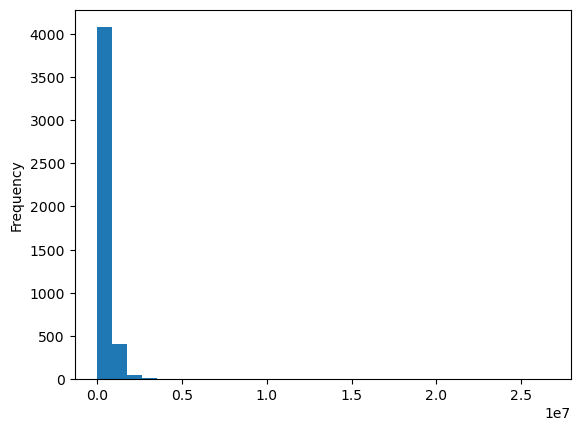

In [24]:
#check the price distribution
df['price'].plot(kind='hist', bins=30)

<Axes: xlabel='sqft_living', ylabel='price'>

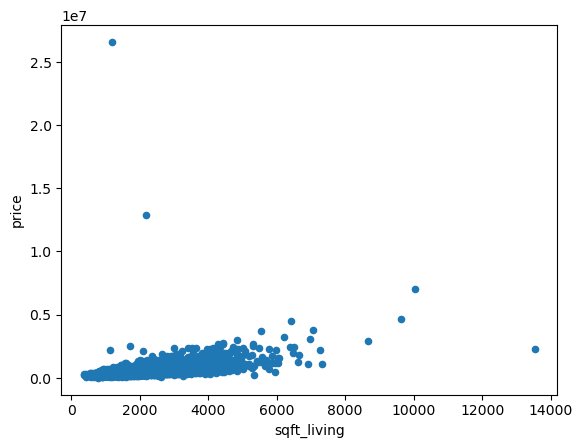

In [25]:
#check the relationship between house size and price
df.plot.scatter(x='sqft_living', y='price')

<Axes: xlabel='bedrooms', ylabel='price'>

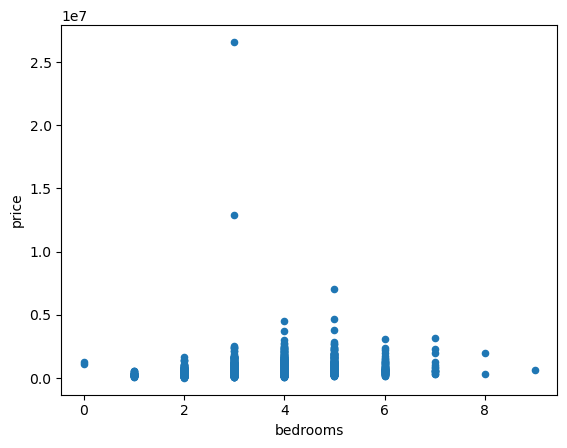

In [26]:
#check the number of bedrooms vs price
df.plot.scatter(x='bedrooms',y='price')

<Axes: xlabel='bathrooms', ylabel='price'>

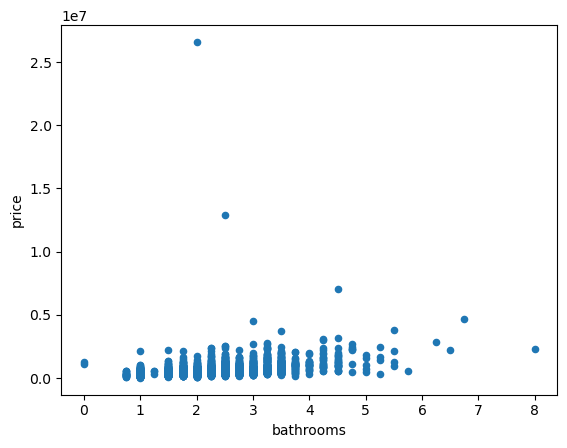

In [27]:
#bathrooms vs price
df.plot.scatter(x='bathrooms',y='price')

<Axes: xlabel='floors', ylabel='price'>

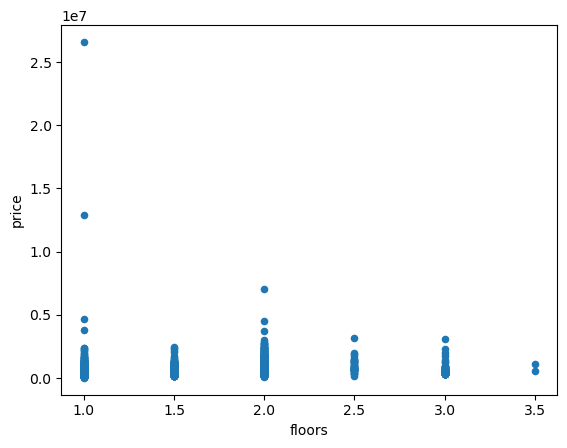

In [28]:
#floors vs price
df.plot.scatter(x='floors',y='price')

In [29]:
#waterfront vs price
df.groupby('waterfront')['price'].mean()

waterfront
0    5.510122e+05
1    1.596783e+06
Name: price, dtype: float64

In [30]:
#condition vs price
df.groupby('condition')['price'].mean()

condition
1    306633.333333
2    334837.419355
3    554742.409548
4    539682.069596
5    652030.529835
Name: price, dtype: float64

In [31]:
#view vs price
df.groupby('view')['price'].mean()

view
0    5.152902e+05
1    8.670110e+05
2    8.250335e+05
3    1.006888e+06
4    1.322963e+06
Name: price, dtype: float64

<Axes: xlabel='yr_built', ylabel='price'>

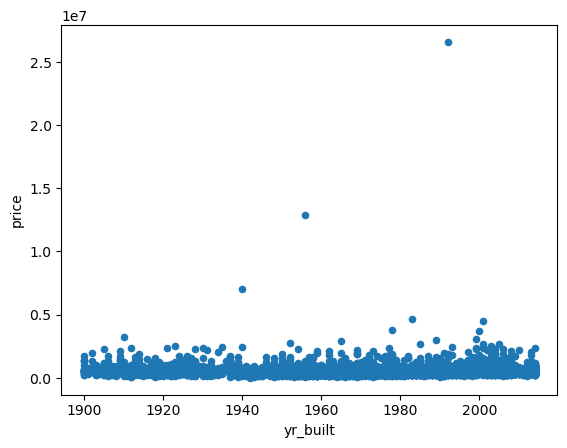

In [32]:
#yr_built vs price
df.plot.scatter(x='yr_built',y='price')

<Axes: xlabel='sqft_lot', ylabel='price'>

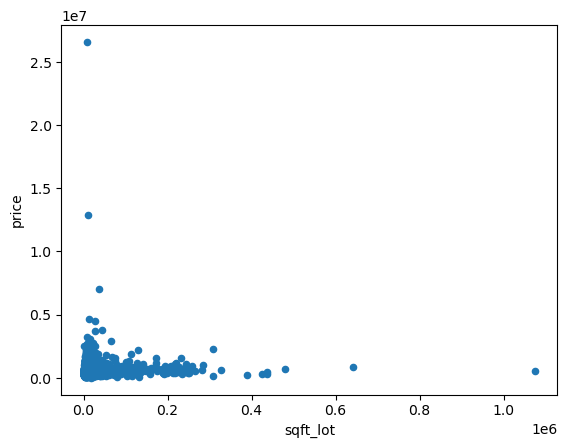

In [33]:
#sqft_lot vs price
df.plot.scatter(x='sqft_lot',y='price')

<Axes: xlabel='sqft_above', ylabel='price'>

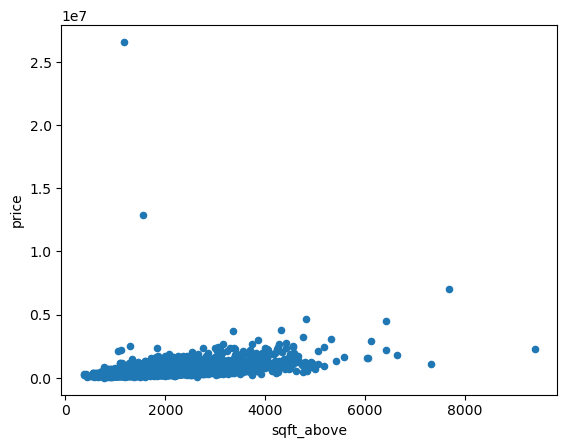

In [34]:
#sqft_above vs price
df.plot.scatter(x='sqft_above',y='price')

<Axes: xlabel='sqft_basement', ylabel='price'>

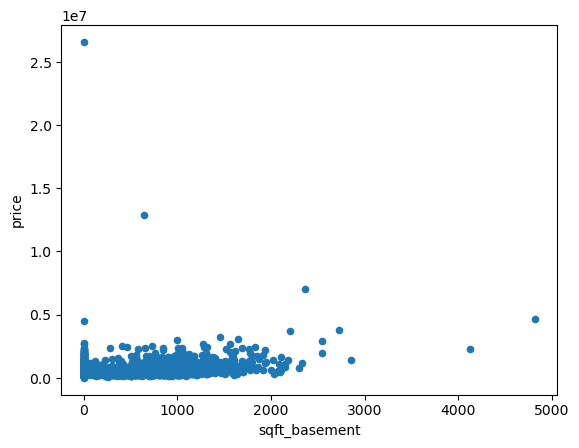

In [35]:
#sqft_basement vs price
df.plot.scatter(x='sqft_basement',y='price')

<Axes: xlabel='yr_renovated', ylabel='price'>

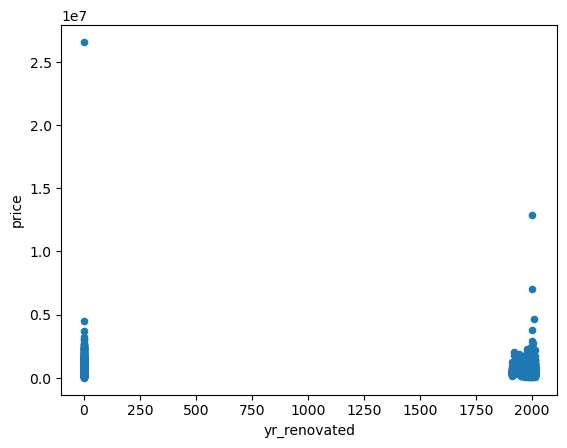

In [36]:
#yr_renovated vs price
df.plot.scatter(x='yr_renovated',y='price')

In [37]:
#city vs price
df.groupby('city')['price'].mean().sort_values(ascending=False)

city
Medina                 2.046559e+06
Clyde Hill             1.615711e+06
Yarrow Point           1.194838e+06
Mercer Island          1.178638e+06
Bellevue               8.622551e+05
Beaux Arts Village     7.450000e+05
Sammamish              7.029858e+05
Fall City              6.926818e+05
Redmond                6.676495e+05
Newcastle              6.660467e+05
Kirkland               6.515836e+05
Woodinville            6.149121e+05
Issaquah               5.993689e+05
Seattle                5.842949e+05
Preston                5.624500e+05
Snoqualmie             5.518504e+05
Normandy Park          5.366044e+05
Snoqualmie Pass        5.250000e+05
Ravensdale             5.140714e+05
Carnation              5.087520e+05
Bothell                4.814419e+05
Lake Forest Park       4.748559e+05
Vashon                 4.725569e+05
Kenmore                4.543786e+05
Kent                   4.418810e+05
Inglewood-Finn Hill    4.250000e+05
Shoreline              4.203924e+05
Duvall                 

In [38]:
#statezip vs price
df.groupby('statezip')['price'].mean().sort_values(ascending=False).head(10)

statezip
WA 98039    2.046559e+06
WA 98004    1.372758e+06
WA 98040    1.178638e+06
WA 98109    1.049846e+06
WA 98112    1.001604e+06
WA 98199    9.572357e+05
WA 98105    9.327018e+05
WA 98119    9.144415e+05
WA 98033    8.164085e+05
WA 98006    8.003283e+05
Name: price, dtype: float64

<Axes: xlabel='price_per_sqft', ylabel='price'>

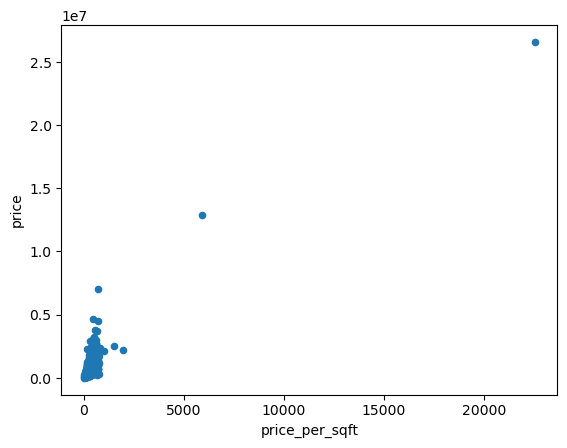

In [39]:
#price_per_sqft vs price
df.plot.scatter(x='price_per_sqft',y='price')

<Axes: xlabel='city'>

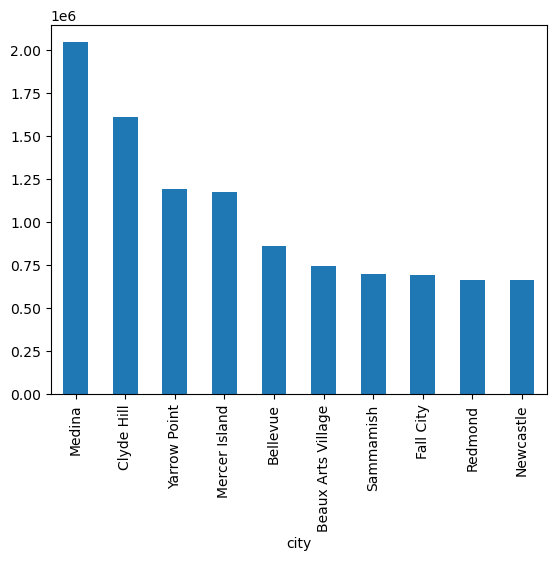

In [40]:
#check whether house location('city') and price have any relationship visually
df.groupby('city')['price'].mean().sort_values(ascending=False).head(10).plot(kind='bar')

<Axes: xlabel='statezip'>

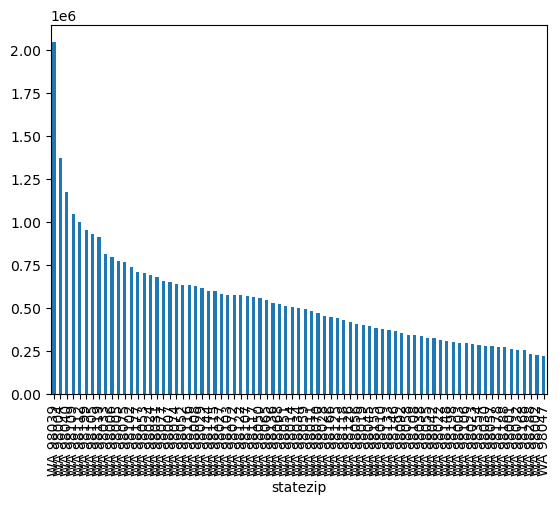

In [41]:
#statezip vs price
df.groupby('statezip')['price'].mean().sort_values(ascending=False).plot(kind='bar')

<Axes: ylabel='Frequency'>

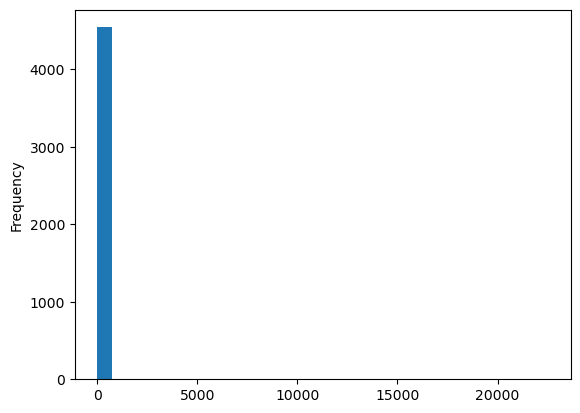

In [42]:
#price per square foot
df['price_per_sqft'].plot(kind='hist',bins=30)

In [43]:
#checking
(df['price_per_sqft']==0).sum()

0

<Axes: >

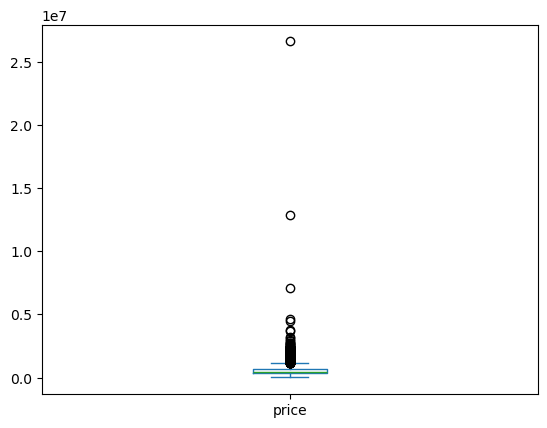

In [44]:
#check price outliers
df['price'].plot(kind='box')

In [45]:
#correlation sqft_living vs price
df['sqft_living'].corr(df['price'])

0.4454937084825276

In [46]:
#correlation between all numeric features
df.corr(numeric_only=True)['price'].sort_values(ascending=False)

price             1.000000
price_per_sqft    0.818099
sqft_living       0.445494
sqft_above        0.380661
bathrooms         0.341126
view              0.242587
sqft_basement     0.217782
bedrooms          0.210228
floors            0.152758
waterfront        0.150083
sqft_lot          0.051347
condition         0.038892
yr_built          0.021757
yr_renovated     -0.029034
Name: price, dtype: float64

<Axes: >

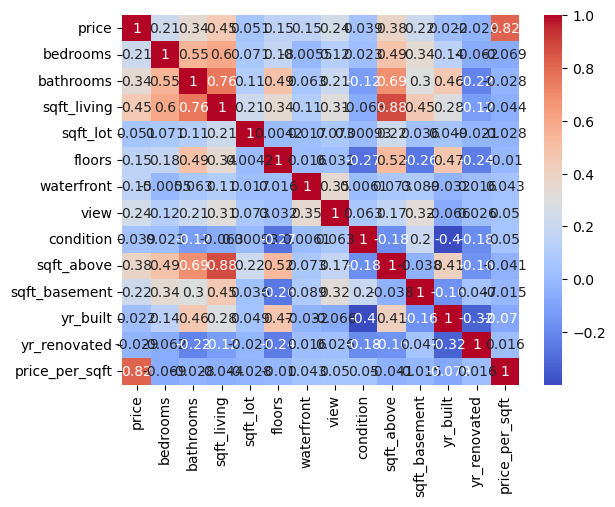

In [47]:
#correlation heatmap
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

In [48]:
#check categorical features (it is check how many unique values)
df['street'].nunique()

4476

In [49]:
#it is the 'statezip' unique values
df['statezip'].nunique()

77

In [50]:
#check city unique values
df['city'].nunique()

44

In [51]:
#check the date column
df['date'].nunique()

70

In [52]:
df['date'].head()

0    2014-05-02
1    2014-05-02
2    2014-05-02
3    2014-05-02
4    2014-05-02
Name: date, dtype: object

In [53]:
df['date'].nunique()

70

In [54]:
#check the date range
df['date'].min(),df['date'].max()

('2014-05-02', '2014-07-10')

In [55]:
#check the date distribution
df['date'].value_counts().sort_index()

date
2014-05-02     67
2014-05-03      4
2014-05-04      5
2014-05-05     81
2014-05-06     82
             ... 
2014-07-06      3
2014-07-07     83
2014-07-08    126
2014-07-09    121
2014-07-10     31
Name: count, Length: 70, dtype: int64

In [56]:
#date vs price
df.groupby('date')['price'].mean()

date
2014-05-02    525538.475522
2014-05-03    466970.000000
2014-05-04    576690.000000
2014-05-05    607773.936173
2014-05-06    523781.821098
                  ...      
2014-07-06    709930.000000
2014-07-07    527370.791205
2014-07-08    545192.127302
2014-07-09    565763.193884
2014-07-10    570716.322581
Name: price, Length: 70, dtype: float64

In [57]:
#check the target distribution with median vs mean
df['price'].mean(),df['price'].median()

(557905.8991342562, 465000.0)

In [58]:
#identify the most useful numeric features for prediction,while excluding the target-leakage future price_per_sqft
df.corr(numeric_only=True)['price'].drop('price_per_sqft').sort_values(ascending=False)

price            1.000000
sqft_living      0.445494
sqft_above       0.380661
bathrooms        0.341126
view             0.242587
sqft_basement    0.217782
bedrooms         0.210228
floors           0.152758
waterfront       0.150083
sqft_lot         0.051347
condition        0.038892
yr_built         0.021757
yr_renovated    -0.029034
Name: price, dtype: float64

In [59]:
#decide which columns need attention before ML
df.select_dtypes(include='object').columns

Index(['date', 'street', 'city', 'statezip'], dtype='object')

In [60]:
#Remaining coulumns
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'price_per_sqft'],
      dtype='object')

In [61]:
features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated',
    'city',
    'statezip'
]

len(features)

14

In [62]:
#create x and y
#X=input features used to make predictions
#y=target/output we want to predict
X = df[features]
y = df['price']

X.shape,y.shape

((4551, 14), (4551,))

In [63]:
#train and test split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [64]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((3640, 14), (911, 14), (3640,), (911,))

In [65]:
#categorical features and OneHotEncoding
categorical_features = ['city','statezip']

In [66]:
numeric_features = [
    'bedrooms',
    'bathrooms',
    'sqft_living',
    'sqft_lot',
    'floors',
    'waterfront',
    'view',
    'condition',
    'sqft_above',
    'sqft_basement',
    'yr_built',
    'yr_renovated'
]

In [67]:
len(categorical_features), len(numeric_features)

(2, 12)

In [68]:
#create the transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough'
)

In [69]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [70]:
X_train_processed.shape, X_test_processed.shape

((3640, 131), (911, 131))

In [71]:
#Train the first ML model
model = LinearRegression()

In [72]:
#Start to train the model
model.fit(X_train_processed, y_train)

LinearRegression()

In [73]:
#Make a predictions
y_pred = model.predict(X_test_processed)

In [74]:
y_pred[:5]

array([1327407.32909575,  550016.67578534,  610617.25368298,
        182115.04847244,  534985.21463463])

In [75]:
#Mean Absolute Error(MAE)
mae = mean_absolute_error(y_test,y_pred)
mae

139638.88082000986

In [76]:
#Root Mean Squared Error
rmse = mean_squared_error(y_test,y_pred)**0.5
rmse

232408.83891630475

In [77]:
#R2 Score
r2 = r2_score(y_test,y_pred)
r2

0.636931326457378

In [78]:
#This is the Actual price vs predicted price
comparison = pd.DataFrame({
    'Actual_Price': y_test.values,
    'Predicted_price': y_pred
})

comparison.head(10)

,Actual_Price,Predicted_price
0,1225000.0,1.327407e+06
1,496752.0,5.500167e+05
2,612500.0,6.106173e+05
3,265000.0,1.821150e+05
4,615000.0,5.349852e+05
5,432000.0,5.130958e+05
6,305000.0,2.603760e+05
7,405000.0,8.943430e+04
8,349000.0,5.204343e+05
9,839000.0,6.963769e+05


In [79]:
#Desicion Tree Regressor
tree_model = DecisionTreeRegressor(
    random_state = 42,
    max_depth = 10
)

In [80]:
tree_model.fit(X_train_processed, y_train)

DecisionTreeRegressor(max_depth=10, random_state=42)

In [81]:
#Make a predictions
tree_pred = tree_model.predict(X_test_processed)

In [82]:
tree_pred[:5]

array([997173.11111111, 547429.34380531, 585836.18828431, 238168.90740426,
       674268.47766667])

In [83]:
#Descison Tree MAE
tree_mae = mean_absolute_error(y_test,tree_pred)
tree_mae

177640.8916526198

In [84]:
#Decision Tree RMSE
tree_rmse = mean_squared_error(y_test,tree_pred)**0.5
tree_rmse

922060.56986692

In [85]:
#Decision Tree R2 score
tree_r2 = r2_score(y_test,tree_pred)
tree_r2

-4.714817919211423

In [86]:
#Random Forest regression
rf_model = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42,
    n_jobs = -1
)

In [87]:
#Train Random Forest
rf_model.fit(X_train_processed, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [88]:
rf_pred = rf_model.predict(X_test_processed)

In [89]:
rf_pred[:5]

array([1128761.98  ,  548260.9467,  540826.0221,  254650.2726,
        637580.2   ])

In [90]:
#Random Forest MAE
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mae

130460.0711165961

In [91]:
#Random Forest RMSE
rf_rmse = mean_squared_error(y_test, rf_pred)**0.5
rf_rmse

527342.8119276217

In [92]:
rf_r2 = r2_score(y_test, rf_pred)
rf_r2

-0.86925933326896

In [93]:
#Check the target values
y_test.describe()

count    9.110000e+02
mean     5.564970e+05
std      3.859195e+05
min      8.435000e+04
25%      3.262500e+05
50%      4.749000e+05
75%      6.650000e+05
max      4.668000e+06
Name: price, dtype: float64

In [94]:
#Check prediction values
rf_pred.min(), rf_pred.max(), rf_pred.mean()

(139134.05, 14476593.3333, 579510.3188872511)

In [95]:
#Find the largest Random Forest prediction
rf_pred.argmax(), rf_pred.max, y_test.iloc[rf_pred.argmax()]

(895, <function ndarray.max>, 250000.0)

In [96]:
#Check the maximum Random Foresh Prediction
rf_pred.max()

14476593.3333

In [97]:
#Find the house with this prediction
rf_pred.argmax()

895

In [98]:
#Compare predicted vs actual price
rf_pred[895], y_test.iloc[895]

(14476593.3333, 250000.0)

In [99]:
#Inspect the test row
X_test.iloc[895]

bedrooms              3.0
bathrooms            1.75
sqft_living          1200
sqft_lot            24805
floors                1.0
waterfront              0
view                    0
condition               3
sqft_above           1200
sqft_basement           0
yr_built             1984
yr_renovated            0
city                 Kent
statezip         WA 98031
Name: 3833, dtype: object

In [100]:
#Check how many similar houses are in the training data
X_train[X_train['statezip'] == 'WA 98091'].shape

(0, 14)

In [101]:
#Checking the city
X_train[X_train['city'] == 'kent'].shape

(0, 14)

In [102]:
#Compare this house with the training data
X_train[numeric_features].describe()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,3640.000000,3640.000000,3640.000000,3.640000e+03,3640.000000,3640.000000,3640.000000,3640.000000,3640.000000,3640.000000,3640.000000,3640.000000
mean,3.381593,2.148077,2123.163187,1.471758e+04,1.511676,0.005769,0.230220,3.453022,1814.077747,309.085440,1970.344780,798.894505
std,0.905688,0.765683,934.109318,3.670032e+04,0.535175,0.075746,0.758043,0.681069,844.892650,451.610365,29.999324,977.548582
min,0.000000,0.000000,380.000000,7.040000e+02,1.000000,0.000000,0.000000,1.000000,380.000000,0.000000,1900.000000,0.000000
25%,3.000000,1.750000,1460.000000,5.000000e+03,1.000000,0.000000,0.000000,3.000000,1180.000000,0.000000,1950.000000,0.000000
50%,3.000000,2.250000,1970.000000,7.641000e+03,1.500000,0.000000,0.000000,3.000000,1580.000000,0.000000,1975.000000,0.000000
75%,4.000000,2.500000,2600.000000,1.094875e+04,2.000000,0.000000,0.000000,4.000000,2287.000000,600.000000,1996.000000,1999.000000
max,9.000000,6.500000,10040.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,7680.000000,2850.000000,2014.000000,2014.000000


In [103]:
#Check individual tree predictions
rf_tree_predictions = np.array([
    tree.predict(X_test_processed[895])[0]
    for tree in rf_model.estimators_
])

rf_tree_predictions.min(), rf_tree_predictions.max(), rf_tree_predictions.mean()

(139000.0, 26590000.0, 14476593.3333)

In [104]:
#Find the extreme training record
y_train.idxmax()

4350

In [105]:
#Inspect that extreme training house
df.loc[4350]

date                     2014-07-03
price                    26590000.0
bedrooms                        3.0
bathrooms                       2.0
sqft_living                    1180
sqft_lot                       7793
floors                          1.0
waterfront                        0
view                              0
condition                         4
sqft_above                     1180
sqft_basement                     0
yr_built                       1992
yr_renovated                      0
street            12005 SE 219th Ct
city                           Kent
statezip                   WA 98031
price_per_sqft              22533.9
Name: 4350, dtype: object

In [106]:
#Check the price distribution for extreme values
df['price'].sort_values(ascending=False).head(10)

4350    26590000.0
4346    12899000.0
2286     7062500.0
2654     4668000.0
2761     4489000.0
3729     3800000.0
1637     3710000.0
252      3200000.0
1567     3100000.0
2772     3000000.0
Name: price, dtype: float64

In [107]:
#Check the top 10 houses features
df.loc[df['price'].nlargest(10).index,['price','sqft_living','bedrooms','bathrooms','city','statezip']]

,price,sqft_living,bedrooms,bathrooms,city,statezip
4350,26590000.0,1180,3.0,2.00,Kent,WA 98031
4346,12899000.0,2190,3.0,2.50,Seattle,WA 98199
2286,7062500.0,10040,5.0,4.50,Bellevue,WA 98004
2654,4668000.0,9640,5.0,6.75,Mercer Island,WA 98040
2761,4489000.0,6430,4.0,3.00,Bellevue,WA 98004
3729,3800000.0,7050,5.0,5.50,Clyde Hill,WA 98004
1637,3710000.0,5550,4.0,3.50,Medina,WA 98039
252,3200000.0,6210,7.0,4.50,Seattle,WA 98109
1567,3100000.0,6980,6.0,4.25,Mercer Island,WA 98040
2772,3000000.0,4850,4.0,4.25,Kirkland,WA 98034


In [108]:
#Check whethter row 4350 is actually in the training set
4350 in X_train.index, 4350 in y_train.index

(True, True)

In [109]:
#Check row 4350 in training features
X_train.loc[4350, ['city','statezip','sqft_living','bedrooms','bathrooms']]

city               Kent
statezip       WA 98031
sqft_living        1180
bedrooms            3.0
bathrooms           2.0
Name: 4350, dtype: object

In [110]:
#Recheck how many WA 98031 houses are in the training
X_train[X_train['statezip'] == 'WA 98031'].shape

(52, 14)

In [111]:
X_train[X_train['city'] == 'Kent'].shape

(145, 14)

In [112]:
#Check the other WA 98031 houses
X_train[X_train['statezip'] == 'WA 98031'][['sqft_living','bedrooms','bathrooms']]

,sqft_living,bedrooms,bathrooms
3307,1050,3.0,1.00
657,2220,3.0,2.50
1957,2490,5.0,2.50
3428,3200,4.0,2.50
4072,2200,4.0,2.50
3869,1310,2.0,1.00
2111,1980,4.0,2.50
1497,740,2.0,1.00
1289,1490,3.0,2.00
2751,1820,4.0,1.75


In [113]:
y_train[X_train['statezip'] == 'WA 98031'].sort_values(ascending=False).head(10)

4350    26590000.0
1152      430000.0
3580      399950.0
3857      394500.0
3428      385000.0
2677      382500.0
2160      364900.0
3466      354000.0
3717      328950.0
3653      327500.0
Name: price, dtype: float64

In [114]:
#Verify suspicious row against nearby prices
X_train.loc[4350, ['sqft_living','bedrooms','bathrooms','sqft_lot','city','statezip']]

sqft_living        1180
bedrooms            3.0
bathrooms           2.0
sqft_lot           7793
city               Kent
statezip       WA 98031
Name: 4350, dtype: object

In [115]:
y_train.loc[4350]

26590000.0

In [116]:
#Check how many extreme-price houses exists
df[df['price'] > 5000000][['price','sqft_living','bedrooms','bathrooms','city','statezip']]

,price,sqft_living,bedrooms,bathrooms,city,statezip
2286,7062500.0,10040,5.0,4.5,Bellevue,WA 98004
4346,12899000.0,2190,3.0,2.5,Seattle,WA 98199
4350,26590000.0,1180,3.0,2.0,Kent,WA 98031


In [117]:
df[df['price'] > 5000000][['price','sqft_living','price_per_sqft','city','statezip']]

,price,sqft_living,price_per_sqft,city,statezip
2286,7062500.0,10040,703.44,Bellevue,WA 98004
4346,12899000.0,2190,5889.95,Seattle,WA 98199
4350,26590000.0,1180,22533.90,Kent,WA 98031


In [118]:
df['price_per_sqft'].describe()

count     4551.000000
mean       268.738862
std        358.351196
min         10.000000
25%        182.890000
50%        245.420000
75%        315.735000
max      22533.900000
Name: price_per_sqft, dtype: float64

In [119]:
df = df[df['price_per_sqft'] < 1000]

In [120]:
df.shape

(4546, 18)

In [121]:
df['price_per_sqft'].max()

800.0

In [122]:
df['price_per_sqft'].min()

10.0

In [123]:
df[df['price_per_sqft'] == 10]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
4351,2014-05-06,7800.0,2.0,1.0,780,16344,1.0,0,0,1,780,0,1942,0,4229 S 144th St,Tukwila,WA 98168,10.0


In [124]:
df = df[df['price_per_sqft'] > 50] 

In [125]:
df.shape

(4543, 18)

In [126]:
df['price_per_sqft'].describe()

count    4543.000000
mean      261.955050
std       106.631368
min        55.910000
25%       182.930000
50%       245.410000
75%       315.445000
max       800.000000
Name: price_per_sqft, dtype: float64

In [127]:
df.drop('price_per_sqft', axis = 1, inplace=True)

In [128]:
df.shape

(4543, 17)

In [129]:
df.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
dtype: int64

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4543 entries, 0 to 4599
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4543 non-null   object 
 1   price          4543 non-null   float64
 2   bedrooms       4543 non-null   float64
 3   bathrooms      4543 non-null   float64
 4   sqft_living    4543 non-null   int64  
 5   sqft_lot       4543 non-null   int64  
 6   floors         4543 non-null   float64
 7   waterfront     4543 non-null   int64  
 8   view           4543 non-null   int64  
 9   condition      4543 non-null   int64  
 10  sqft_above     4543 non-null   int64  
 11  sqft_basement  4543 non-null   int64  
 12  yr_built       4543 non-null   int64  
 13  yr_renovated   4543 non-null   int64  
 14  street         4543 non-null   object 
 15  city           4543 non-null   object 
 16  statezip       4543 non-null   object 
dtypes: float64(4), int64(9), object(4)
memory usage: 638.9+ K

In [131]:
df['city'].nunique()

44

In [132]:
df['city'].value_counts()

city
Seattle                1558
Renton                  291
Bellevue                281
Redmond                 235
Kirkland                187
Issaquah                186
Kent                    183
Auburn                  175
Sammamish               171
Federal Way             145
Shoreline               123
Woodinville             114
Maple Valley             95
Mercer Island            82
Burien                   72
Snoqualmie               69
Kenmore                  65
Des Moines               58
North Bend               50
Duvall                   42
Covington                41
Lake Forest Park         34
Bothell                  33
Newcastle                33
Vashon                   29
SeaTac                   28
Enumclaw                 27
Tukwila                  27
Carnation                22
Normandy Park            17
Medina                   11
Fall City                11
Clyde Hill                9
Black Diamond             8
Ravensdale                7
Pacific        

In [133]:
len(df.city.unique())

44

In [134]:
df.city = df.city.apply(lambda x: 'other' if df.city.value_counts()[x] <= 10 else x)

In [135]:
df.city.value_counts()

city
Seattle             1558
Renton               291
Bellevue             281
Redmond              235
Kirkland             187
Issaquah             186
Kent                 183
Auburn               175
Sammamish            171
Federal Way          145
Shoreline            123
Woodinville          114
Maple Valley          95
Mercer Island         82
Burien                72
Snoqualmie            69
Kenmore               65
Des Moines            58
North Bend            50
other                 48
Duvall                42
Covington             41
Lake Forest Park      34
Newcastle             33
Bothell               33
Vashon                29
SeaTac                28
Tukwila               27
Enumclaw              27
Carnation             22
Normandy Park         17
Fall City             11
Medina                11
Name: count, dtype: int64

In [136]:
len(df.city.unique())

33

In [137]:
city_dummies = pd.get_dummies(df.city,drop_first=True)

In [138]:
df = pd.concat([df,city_dummies],axis=1)

In [139]:
df.drop('city',axis=1,inplace=True)

In [140]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,Renton,Sammamish,SeaTac,Seattle,Shoreline,Snoqualmie,Tukwila,Vashon,Woodinville,other
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,...,False,False,False,False,True,False,False,False,False,False
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,...,False,False,False,True,False,False,False,False,False,False
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,...,False,False,False,False,False,False,False,False,False,False
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,...,False,False,False,False,False,False,False,False,False,False
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,...,False,False,False,False,False,False,False,False,False,False


In [141]:
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'statezip',
       'Bellevue', 'Bothell', 'Burien', 'Carnation', 'Covington', 'Des Moines',
       'Duvall', 'Enumclaw', 'Fall City', 'Federal Way', 'Issaquah', 'Kenmore',
       'Kent', 'Kirkland', 'Lake Forest Park', 'Maple Valley', 'Medina',
       'Mercer Island', 'Newcastle', 'Normandy Park', 'North Bend', 'Redmond',
       'Renton', 'Sammamish', 'SeaTac', 'Seattle', 'Shoreline', 'Snoqualmie',
       'Tukwila', 'Vashon', 'Woodinville', 'other'],
      dtype='object')

In [142]:
df['statezip'].nunique()

77

In [143]:
df.statezip = df.statezip.apply(lambda x:x.split(' ')[1])

In [144]:
df['statezip'].head()

0    98133
1    98119
2    98042
3    98008
4    98052
Name: statezip, dtype: object

In [145]:
statezip_dummies = pd.get_dummies(df.statezip,drop_first=True)

In [146]:
df = pd.concat([df,statezip_dummies],axis=1)

In [147]:
df.drop('statezip',axis=1,inplace=True)

In [148]:
df.shape

(4543, 123)

In [149]:
df.drop(['date','street'],axis=1,inplace=True)

In [150]:
df.shape

(4543, 121)

In [151]:
X_train.select_dtypes(include='object').columns

Index(['city', 'statezip'], dtype='object')

In [152]:
X = df.drop('price',axis=1)
y = df['price']

In [153]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [154]:
X_train.select_dtypes(include='object').columns

Index([], dtype='object')

In [155]:
model.fit(X_train,y_train)

LinearRegression()

In [156]:
model.score(X_test,y_test)

-168.6029665030255

In [157]:
y_pred = model.predict(X_test)

In [158]:
mean_absolute_error(y_test,y_pred)

258943.29366971322

In [159]:
pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
}).head(10)

,Actual,Predicted
1647,325000.0,4.741546e+05
1476,745000.0,1.161610e+06
2111,307550.0,2.780353e+05
3612,300000.0,2.863781e+05
691,253000.0,3.332981e+05
2655,170000.0,2.382644e+05
1662,1595000.0,9.485032e+05
3250,362500.0,3.086244e+05
415,280000.0,2.900177e+05
3288,597326.0,1.173023e+06


In [160]:
X.describe()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4543.000000,4543.000000,4543.000000,4.543000e+03,4543.000000,4543.000000,4543.000000,4543.000000,4543.000000,4543.000000,4543.000000,4543.000000
mean,3.394453,2.155239,2132.374202,1.484403e+04,1.512327,0.006604,0.234427,3.449483,1822.491966,309.882236,1970.813339,807.791988
std,0.904651,0.776195,955.123752,3.599458e+04,0.538441,0.081002,0.764891,0.674136,854.269287,461.747497,29.762415,979.271871
min,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.000000,1.750000,1460.000000,5.000000e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,3.000000,2.250000,1970.000000,7.680000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,4.000000,2.500000,2610.000000,1.096600e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,600.000000,1997.000000,1999.000000
max,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


In [161]:
df[['sqft_lot','price']].sort_values(by='sqft_lot', ascending=False).head()

,sqft_lot,price
1078,1074218,542500.0
2480,641203,849900.0
3487,478288,667000.0
879,435600,480000.0
375,435600,330000.0


In [162]:
len(df[df['sqft_lot'] > 100000])

100

In [163]:
df = df[df['sqft_lot'] < 100000]

In [164]:
df.shape

(4443, 121)

In [165]:
X = df.drop('price',axis=1)
y = df['price']

In [166]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [167]:
model.fit(X_train, y_train)

LinearRegression()

In [168]:
model.score(X_test,y_test)

0.7928854092269338

In [169]:
y_pred = model.predict(X_test)

In [170]:
r2_score(y_test,y_pred)

0.7928854092269338

In [171]:
mean_absolute_error(y_test,y_pred)

100934.05926012671

In [172]:
mean_squared_error(y_test,y_pred)

29724774830.486496

In [173]:
mean_squared_error(y_test,y_pred,squared=False)

D:\Anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


172408.74348618893

In [174]:
np.sqrt(mean_squared_error(y_test,y_pred))

172408.74348618893

In [175]:
model.score(X_train,y_train)

0.7897842637743717

In [176]:
#Check the model coefficient
model.coef_

array([-2.96547902e+04,  2.00794332e+04, -5.68720186e+12,  3.88662052e-01,
       -2.31164234e+04,  6.07119181e+05,  6.29938236e+04,  2.93915228e+04,
        5.68720187e+12,  5.68720187e+12, -2.54932617e+02,  7.93896484e+00,
       -4.06095879e+05,  2.45958760e+09,  1.57641899e+07,  5.33193492e+08,
        3.18388344e+08,  1.58530582e+07, -1.36890030e+07,  2.77715624e+06,
        2.17199558e+07, -1.05101189e+05, -1.24359722e+09,  2.45955050e+09,
        3.18385750e+08, -2.41512570e+04,  1.56374114e+07,  9.70512323e+07,
        6.51054744e+06, -2.44798211e+07,  5.27862567e+08,  1.58635485e+07,
       -1.48987487e+07, -1.24357917e+09,  5.27746667e+08, -1.24360104e+09,
        1.57975847e+07,  1.57975815e+07,  1.56914115e+07, -1.40773521e+06,
        1.57513352e+07,  3.89257924e+07, -5.08573956e+08, -3.75863520e+04,
        7.11450470e+03,  8.14878713e+04,  1.11993279e+06,  7.32802690e+05,
        6.87451060e+05,  7.00404363e+05,  6.28191850e+05,  1.38973576e+05,
       -2.45948158e+09, -

In [177]:
#The model's baseline predicted house price 
model.intercept_

315564.7819836803

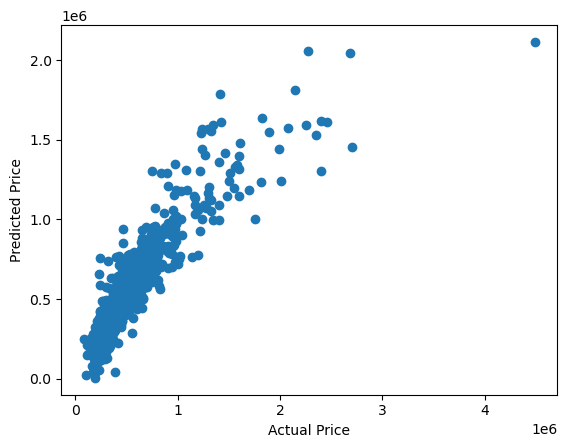

In [178]:
plt.scatter(y_test,y_pred)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()

In [179]:
pd.DataFrame({
    'Features': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient',ascending=False).head(10)

,Features,Coefficient
8,sqft_above,5.687202e+12
9,sqft_basement,5.687202e+12
13,Bothell,2.459588e+09
23,Kenmore,2.459551e+09
60,98029,1.243840e+09
74,98052,1.243835e+09
86,98075,1.243794e+09
75,98053,1.243787e+09
85,98074,1.243780e+09
58,98027,1.243747e+09


In [180]:
df[['sqft_living','sqft_above','sqft_basement']].corr()

,sqft_living,sqft_above,sqft_basement
sqft_living,1.000000,0.867747,0.445692
sqft_above,0.867747,1.000000,-0.058165
sqft_basement,0.445692,-0.058165,1.000000


In [181]:
df = df.drop('sqft_living',axis=1)

In [182]:
X = df.drop('price',axis=1)
y = df['price']

In [183]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [184]:
model.fit(X_train,y_train)

LinearRegression()

In [185]:
model.score(X_test,y_test)

0.7928841611610005

In [186]:
#It is formula to adjust R2
n = X_test.shape[0]
p = X_test.shape[1]
r2 = r2_score(y_test,y_pred)

adj_r2 = 1 - (1-r2)*(n-1)/(n-p-1)
adj_r2

0.7608351669616609

In [187]:
dt_model = DecisionTreeRegressor(random_state=42)

In [188]:
dt_model.fit(X_train,y_train)

DecisionTreeRegressor(random_state=42)

In [189]:
dt_model.score(X_test,y_test)

0.48537458232915986

In [190]:
dt_model.score(X_train,y_train)

0.9999958712568997

In [191]:
rf_model = RandomForestRegressor(random_state=42)

In [192]:
rf_model.fit(X_train,y_train)

RandomForestRegressor(random_state=42)

In [193]:
rf_model.score(X_test,y_test)

0.7223914467910295

In [194]:
rf_model.score(X_train,y_train)

0.9634852051439721

In [195]:
cross_val_score(model,X,y,cv=5).mean()

0.7735398812976395

In [196]:
X.columns

Index(['bedrooms', 'bathrooms', 'sqft_lot', 'floors', 'waterfront', 'view',
       'condition', 'sqft_above', 'sqft_basement', 'yr_built',
       ...
       '98155', '98166', '98168', '98177', '98178', '98188', '98198', '98199',
       '98288', '98354'],
      dtype='object', length=119)

In [197]:
list(X.columns)

['bedrooms',
 'bathrooms',
 'sqft_lot',
 'floors',
 'waterfront',
 'view',
 'condition',
 'sqft_above',
 'sqft_basement',
 'yr_built',
 'yr_renovated',
 'Bellevue',
 'Bothell',
 'Burien',
 'Carnation',
 'Covington',
 'Des Moines',
 'Duvall',
 'Enumclaw',
 'Fall City',
 'Federal Way',
 'Issaquah',
 'Kenmore',
 'Kent',
 'Kirkland',
 'Lake Forest Park',
 'Maple Valley',
 'Medina',
 'Mercer Island',
 'Newcastle',
 'Normandy Park',
 'North Bend',
 'Redmond',
 'Renton',
 'Sammamish',
 'SeaTac',
 'Seattle',
 'Shoreline',
 'Snoqualmie',
 'Tukwila',
 'Vashon',
 'Woodinville',
 'other',
 '98002',
 '98003',
 '98004',
 '98005',
 '98006',
 '98007',
 '98008',
 '98010',
 '98011',
 '98014',
 '98019',
 '98022',
 '98023',
 '98024',
 '98027',
 '98028',
 '98029',
 '98030',
 '98031',
 '98032',
 '98033',
 '98034',
 '98038',
 '98039',
 '98040',
 '98042',
 '98045',
 '98047',
 '98050',
 '98051',
 '98052',
 '98053',
 '98055',
 '98056',
 '98057',
 '98058',
 '98059',
 '98065',
 '98068',
 '98070',
 '98072',
 '9807

In [198]:
X = df[['bedrooms',
'bathrooms',
'sqft_lot',
'floors',
'waterfront',
'view',
'condition',
'sqft_above',
'sqft_basement',
'yr_built',
'yr_renovated']]

In [199]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [200]:
model.fit(X_train,y_train)

LinearRegression()

In [201]:
model.score(X_test,y_test)

0.5813559527297104

In [202]:
pickle.dump(X.columns.tolist(),open('features.pkl','wb'))

In [203]:
pickle.dump(model,open('house_price_model.pki','wb'))

In [204]:
os.listdir()

['.ipynb_checkpoints',
 'app.py',
 'features.pkl',
 'house_price_model.pki',
 'house_price_model.pkl',
 'house_price_prediction.ipynb',
 'modified_data.csv']

In [1214]:
os.getcwd()

'C:\\Users\\Pratik\\House price prediction'

In [ ]:
#Checking of Project

In [408]:
y_pred = model.predict(X_test)

In [410]:
r2_score(y_test,y_pred)

0.5813559527297104

In [412]:
mean_absolute_error(y_test,y_pred)

156419.22890861385

In [414]:
rmse = mean_squared_error(y_test,y_pred)**0.5
rmse

245118.67443210815

In [416]:
df.shape

(4443, 120)

In [418]:
df['price'].describe()

count    4.443000e+03
mean     5.453501e+05
std      3.642260e+05
min      8.000000e+04
25%      3.250000e+05
50%      4.610000e+05
75%      6.500000e+05
max      7.062500e+06
Name: price, dtype: float64

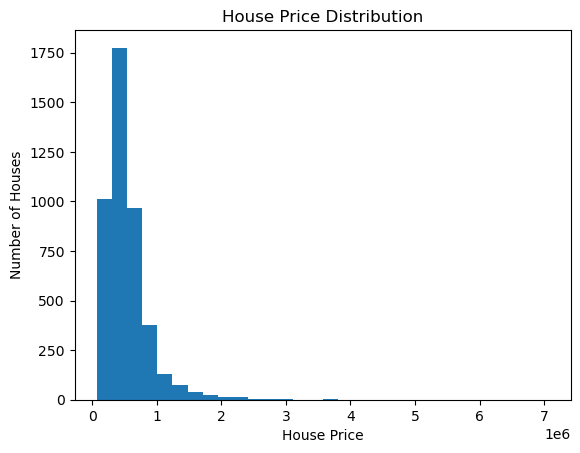

In [420]:
plt.hist(df['price'],bins=30)
plt.xlabel('House Price')
plt.ylabel('Number of Houses')
plt.title('House Price Distribution')
plt.show()

In [424]:
coefficients = pd.Series(model.coef_,index=X.columns)
coefficients.sort_values(ascending=False).head(10)

waterfront       477914.122067
floors            63514.209895
view              56026.119290
bathrooms         49105.557180
condition         29833.897455
sqft_above          281.626889
sqft_basement       269.136355
yr_renovated          9.880940
sqft_lot             -1.867078
yr_built          -2644.703569
dtype: float64

In [426]:
coefficients.sort_values().head(10)

bedrooms        -59574.667608
yr_built         -2644.703569
sqft_lot            -1.867078
yr_renovated         9.880940
sqft_basement      269.136355
sqft_above         281.626889
condition        29833.897455
bathrooms        49105.557180
view             56026.119290
floors           63514.209895
dtype: float64

In [428]:
df.corr(numeric_only=True)['price'].sort_values(ascending=False)

price            1.000000
sqft_above       0.598008
bathrooms        0.516426
view             0.393855
sqft_basement    0.340134
                   ...   
98023           -0.101121
98168           -0.104470
Renton          -0.122576
Federal Way     -0.125817
Kent            -0.140416
Name: price, Length: 120, dtype: float64

Text(0.5, 1.0, 'Actual vs Predicted House Prices')

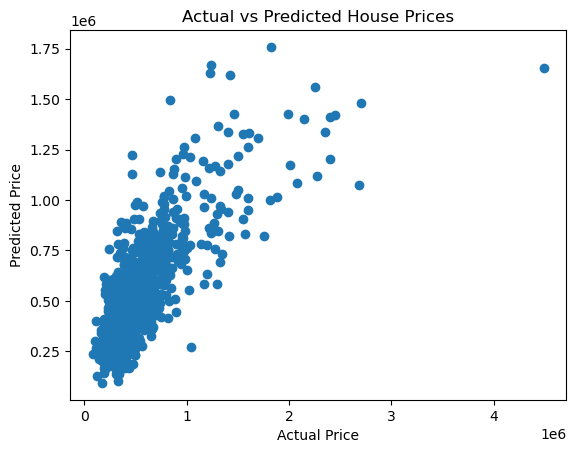

In [430]:
plt.scatter(y_test,y_pred)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')